# 04_multivariate — Analisis Bivariat dan Multivariat (M3)
**Tim:** Yusuf · **Data:** `genshin_impact_clean.csv` (keluaran `01_quality.ipynb`) · **EDA (KMTI21133)**

Lanjutan dari `03_univariate.ipynb`: kini melihat **hubungan antarvariabel**, menjawab P2 dan P3. Pengganti variabel yang dibuang di `01_quality` dijelaskan di notebook 03 (bagian "Data yang dipakai").

| Syarat wajib M3 | Bagian |
|---|---|
| Heatmap Pearson & Spearman berdampingan (`vmin=-1, vmax=1, center=0`) | 1 |
| Dua scatter plot + tafsiran | 2 |
| Crosstab ternormalisasi per baris + Cramér's V | 3 |
| Faceting dari satu scatter plot | 4 |
| Paragraf kandidat variabel perancu | 5 |
| (Tambahan) Uji sensitivitas memakai penanda dari `02_cleaning` | 6 |

> **Aturan:** tidak ada kalimat sebab-akibat ("berkaitan dengan", "cenderung disertai"). Satu baris = satu karakter, bukan pemain.

## 0. Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
FIG = '../reports/figures' if os.path.basename(os.getcwd()) == 'notebooks' else 'reports/figures'
os.makedirs(FIG, exist_ok=True)

# Data hasil 01_quality.ipynb (penanganan data pribadi). Path relatif, tanpa C:\\Users atau /content/drive.
FILE = 'genshin_impact_clean.csv'
KANDIDAT = ['../data/processed/' + FILE, 'data/processed/' + FILE, FILE]
path = next((p for p in KANDIDAT if os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files
        files.upload(); path = FILE
    except ImportError:
        raise FileNotFoundError(f'Letakkan {FILE} di data/processed/ atau di folder yang sama dengan notebook ini.')

df = pd.read_csv(path)
assert df.shape == (103, 24), df.shape        # harus sama dengan keluaran 01_quality (103 baris, 24 kolom)

# kelompok_umur_rilis dibaca sebagai teks dari CSV -> kembalikan sebagai kategori BERURUTAN
URUT_USIA = ['<1 Tahun', '1-2 Tahun', '2-3 Tahun', '3-4 Tahun', '4+ Tahun']
df['kelompok_umur_rilis'] = pd.Categorical(df['kelompok_umur_rilis'], categories=URUT_USIA, ordered=True)
df['usia_rilis_kode'] = df['kelompok_umur_rilis'].cat.codes + 1            # 1 (<1 Tahun) ... 5 (4+ Tahun)

# label dan penanda untuk grafik/analisis (data asli tidak diubah)
df['bintang'] = df['rarity'].astype(str) + '★'
df['standar'] = df['is_standard_banner'].map({0: 'Bukan banner standar', 1: 'Banner standar'})
df['region_ringkas'] = df['region'].where(df['region'].map(df['region'].value_counts()) >= 5, 'Lainnya')   # region < 5 karakter digabung
KOLOM_C = [f'constellation_{i}_pull' for i in range(8)]
df['pulled_tidak_cocok'] = df['pulled_count'] != df[KOLOM_C].sum(axis=1)     # aturan hubungan antarkolom dari 02_cleaning

print('Sumber:', path, '| bentuk:', df.shape, '(24 kolom dari 01_quality + 5 kolom bantu analisis)')
print('Baris pulled_count != total C0-C7:', int(df['pulled_tidak_cocok'].sum()), '(ditandai, tidak dibuang)')

Sumber: ../data/processed/genshin_impact_clean.csv | bentuk: (103, 29) (24 kolom dari 01_quality + 5 kolom bantu analisis)
Baris pulled_count != total C0-C7: 9 (ditandai, tidak dibuang)


## 1. Heatmap korelasi: Pearson dan Spearman berdampingan
> Heatmap dipakai untuk **memilih pasangan**, bukan untuk menyimpulkan. Kedua panel memakai skala warna yang sama.

n untuk korelasi (setelah dropna): 103


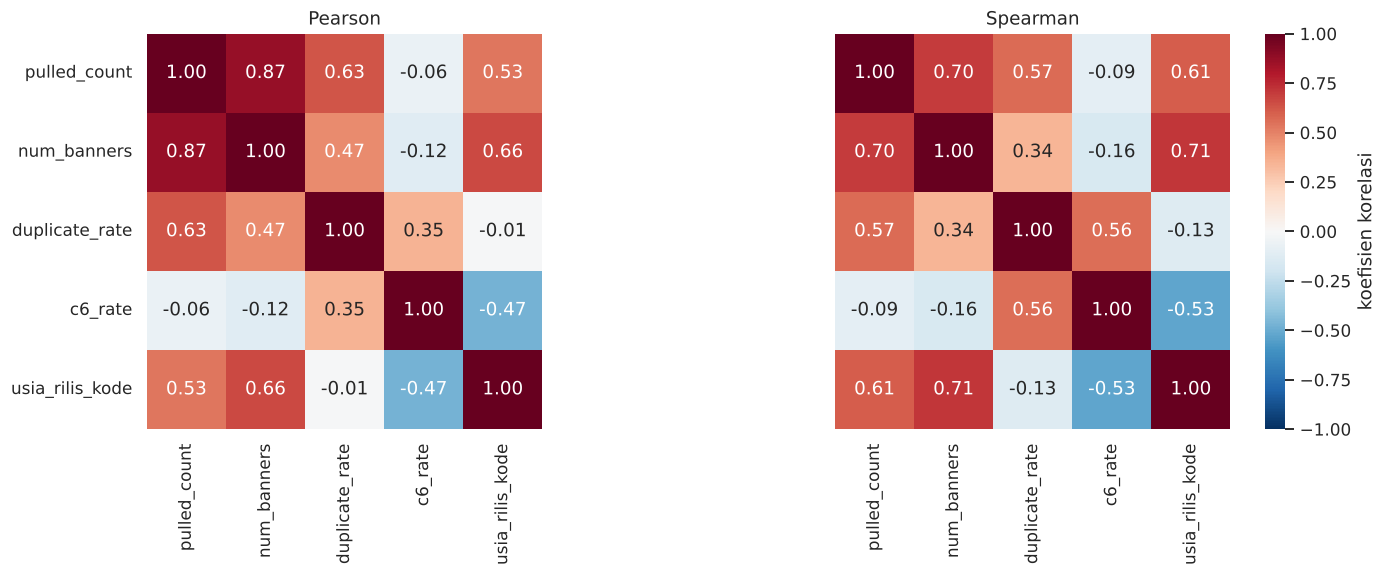

In [2]:
KORELASI = ['pulled_count', 'num_banners', 'duplicate_rate', 'c6_rate', 'usia_rilis_kode']
data_kor = df[KORELASI].dropna()
print('n untuk korelasi (setelah dropna):', len(data_kor))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
for a, metode in zip(ax, ['pearson', 'spearman']):
    sns.heatmap(data_kor.corr(metode), ax=a, annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, center=0, square=True, cbar=(metode == 'spearman'),
                cbar_kws={'label': 'koefisien korelasi'} if metode == 'spearman' else None)
    a.set_title(metode.capitalize())
plt.tight_layout(); plt.savefig(FIG + '/m3_heatmap_pearson_spearman.png', bbox_inches='tight'); plt.show()

**Memilih Pearson atau Spearman (alasan dari sifat data, bukan besar angkanya).**
`pulled_count`, `num_banners`, dan `c6_rate` miring ke kanan (lihat notebook 03), dan `usia_rilis_kode` adalah **ordinal** (5 kelompok), bukan angka yang jaraknya sama.
Karena itu **Spearman dijadikan ukuran utama**; Pearson hanya pembanding, dan Pearson pada `usia_rilis_kode` tidak ditafsirkan. Pilihan ini ditetapkan *sebelum* melihat pasangan mana yang lebih besar.
Contoh nyata mengapa: `num_banners` dengan `pulled_count` bernilai 0,87 di Pearson tetapi 0,70 di Spearman; Pearson terdorong oleh sebagian kecil karakter bintang 4 ber-*pull* sangat besar.

**Pasangan yang dipilih:**
- `num_banners` – `pulled_count` (Spearman 0,70): pasangan terkuat, menjawab P2 (tingkat paparan).
- `duplicate_rate` – `pulled_count` (Spearman 0,57): positif cukup kuat, tetapi `duplicate_rate` terpisah sempurna menurut rarity (notebook 03), sehingga dipilih untuk menguji perancu (P3).
- `kelompok_umur_rilis` – `pulled_count` (Spearman 0,61): karena ordinal, ditampilkan sebagai boxplot per kelompok, bukan scatter.

**Catatan:** `usia_rilis_kode` dan `num_banners` saling berkaitan kuat (Spearman 0,71), jadi pengaruh "usia" dan "paparan banner" sulit dipisahkan. `avg_copies_per_player` tidak dimasukkan karena turunan `duplicate_rate`.

## 2. Dua scatter plot terpilih + boxplot usia rilis
Setiap angka korelasi **wajib** disertai grafiknya. *n* dilaporkan setelah `dropna()`.

num_banners    ~ pulled_count : {'n': 103, 'spearman': np.float64(0.7), 'pearson': np.float64(0.87)}
duplicate_rate ~ pulled_count : {'n': 103, 'spearman': np.float64(0.57), 'pearson': np.float64(0.63)}


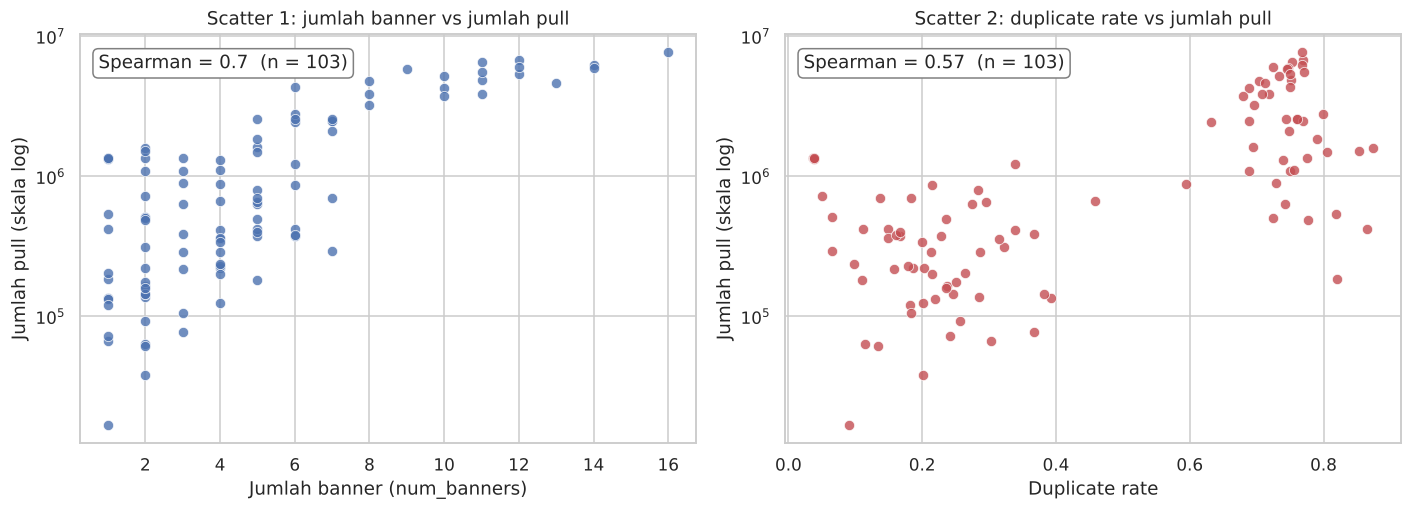

In [3]:
def lapor(x, y, data=df):
    d = data[[x, y]].dropna()
    return dict(n=len(d), spearman=round(stats.spearmanr(d[x], d[y])[0], 2), pearson=round(stats.pearsonr(d[x], d[y])[0], 2))

print('num_banners    ~ pulled_count :', lapor('num_banners', 'pulled_count'))
print('duplicate_rate ~ pulled_count :', lapor('duplicate_rate', 'pulled_count'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
a = ax[0]
sns.scatterplot(data=df, x='num_banners', y='pulled_count', ax=a, color='#4C72B0', s=45, alpha=.8)
a.set(yscale='log', xlabel='Jumlah banner (num_banners)', ylabel='Jumlah pull (skala log)', title='Scatter 1: jumlah banner vs jumlah pull')
a.text(0.03, 0.95, f"Spearman = {lapor('num_banners','pulled_count')['spearman']}  (n = {len(df)})", transform=a.transAxes, va='top', bbox=dict(boxstyle='round', fc='white', ec='gray'))
a = ax[1]
sns.scatterplot(data=df, x='duplicate_rate', y='pulled_count', ax=a, color='#C44E52', s=45, alpha=.8)
a.set(yscale='log', xlabel='Duplicate rate', ylabel='Jumlah pull (skala log)', title='Scatter 2: duplicate rate vs jumlah pull')
a.text(0.03, 0.95, f"Spearman = {lapor('duplicate_rate','pulled_count')['spearman']}  (n = {len(df)})", transform=a.transAxes, va='top', bbox=dict(boxstyle='round', fc='white', ec='gray'))
plt.tight_layout(); plt.savefig(FIG + '/m3_scatter_dua_pasangan.png', bbox_inches='tight'); plt.show()

usia_rilis_kode ~ pulled_count : {'n': 103, 'spearman': np.float64(0.61), 'pearson': np.float64(0.53)} (Pearson tidak ditafsirkan: variabel ordinal)

                     count     median
kelompok_umur_rilis                  
<1 Tahun                17   183773.0
1-2 Tahun               15   177051.0
2-3 Tahun               15   669225.0
3-4 Tahun               17   717953.0
4+ Tahun                39  1342803.0 

                    count         median          
bintang                4★  5★         4★        5★
kelompok_umur_rilis                               
<1 Tahun                6  11   497040.0  121147.0
1-2 Tahun               5  10  1490123.0  151798.0
2-3 Tahun               7   8  1298582.0  222869.0
3-4 Tahun               8   9  2552840.0  359860.0
4+ Tahun               19  20  5201396.0  557986.0


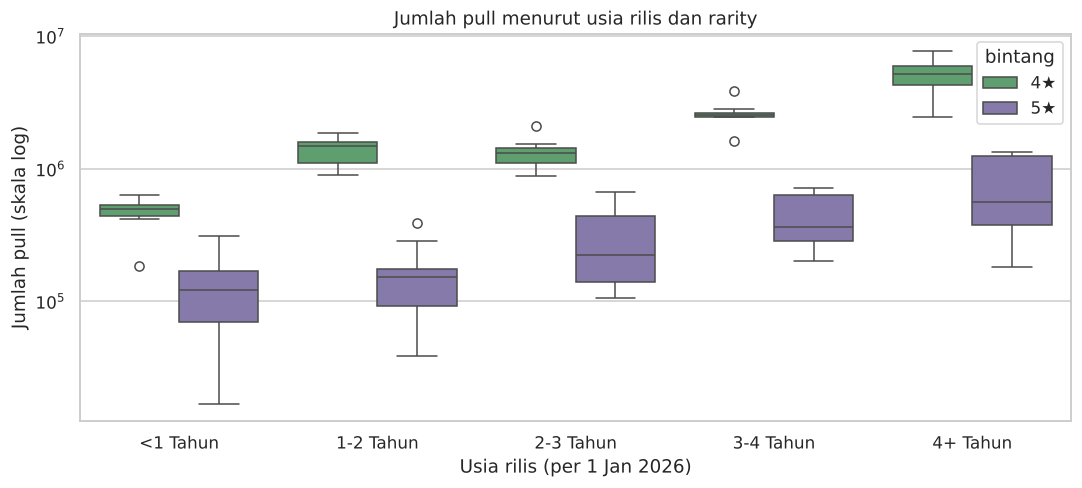

In [4]:
# Usia rilis (ordinal) vs pulled_count: boxplot per kelompok, diwarnai rarity
print('usia_rilis_kode ~ pulled_count :', lapor('usia_rilis_kode', 'pulled_count'), '(Pearson tidak ditafsirkan: variabel ordinal)\n')
print(df.groupby('kelompok_umur_rilis', observed=True)['pulled_count'].agg(['count', 'median']).round(0).to_string(), '\n')
print(df.pivot_table(index='kelompok_umur_rilis', columns='bintang', values='pulled_count', aggfunc=['count', 'median'], observed=True).round(0).to_string())

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.boxplot(data=df, x='kelompok_umur_rilis', y='pulled_count', hue='bintang', hue_order=['4★', '5★'], order=URUT_USIA,
            palette={'4★': '#55A868', '5★': '#8172B2'}, ax=ax)
ax.set(yscale='log', xlabel='Usia rilis (per 1 Jan 2026)', ylabel='Jumlah pull (skala log)', title='Jumlah pull menurut usia rilis dan rarity')
plt.tight_layout(); plt.savefig(FIG + '/m3_boxplot_usia_rilis.png', bbox_inches='tight'); plt.show()

**Tafsiran Scatter 1 (P2).** Karakter yang tampil di lebih banyak banner cenderung disertai jumlah *pull* lebih besar (Spearman 0,70; n = 103). Titiknya membentuk dua "awan" (atas dan bawah), yang diperiksa di bagian 4.
Hubungan ini tidak boleh dibaca sebagai "banner menaikkan *pull*": karakter yang laku bisa saja dihadirkan lebih sering.

**Tafsiran Scatter 2 (P3).** Karakter dengan `duplicate_rate` lebih tinggi cenderung ber-*pull* lebih besar (Spearman 0,57; n = 103), tetapi ada celah kosong pada `duplicate_rate` sekitar 0,46–0,60 dan dua awan titik yang jelas.
Dua awan itu adalah dua kelompok rarity (notebook 03), sehingga hubungan ini perlu diuji ulang setelah rarity dikendalikan (bagian 5).

**Tafsiran usia rilis (P2).** Median *pull* naik bertahap menurut usia rilis (Spearman 0,61; n = 103): sekitar 184 ribu (<1 tahun) dan 177 ribu (1–2 tahun), 669 ribu (2–3), 718 ribu (3–4), dan 1,34 juta (4+ tahun).
Dua kelompok termuda hampir sama, jadi kenaikannya tidak mulus. Di dalam masing-masing rarity arahnya sama (median bintang 4: 0,50 juta menjadi 5,20 juta; bintang 5: 121 ribu menjadi 558 ribu),
tetapi sel per kelompok kecil (5 sampai 20 karakter), sehingga angkanya perkiraan kasar.

## 3. Crosstab ternormalisasi per baris + Cramér's V
Normalisasi **per baris** menjawab: *"dari semua karakter bintang N, berapa persen yang masuk banner standar?"*

Jumlah (n):
standar  Banner standar  Bukan banner standar
bintang                                      
4★                   45                     0
5★                    8                    50 

Persen per baris:
standar  Banner standar  Bukan banner standar
bintang                                      
4★                100.0                   0.0
5★                 13.8                  86.2 

Cramér's V (rarity x banner standar)       = 0.86
Pembanding: Cramér's V (rarity x kelompok_umur_rilis ) = 0.13
Pembanding: Cramér's V (rarity x weapon              ) = 0.22
Pembanding: Cramér's V (rarity x element             ) = 0.14
Pembanding: Cramér's V (rarity x gender              ) = 0.01

standar
Banner standar          2092017.0
Bukan banner standar     232909.0


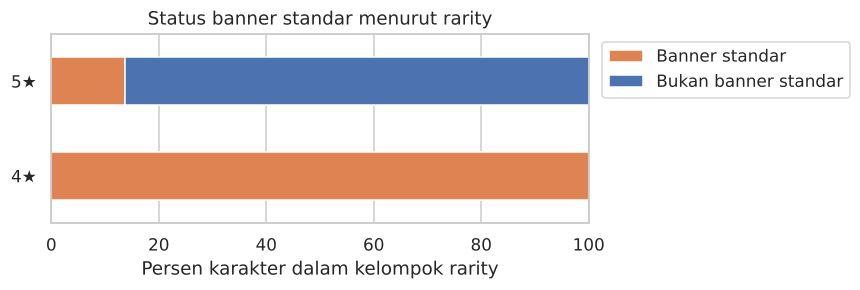

In [5]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

ct_n = pd.crosstab(df['bintang'], df['standar'])
ct_p = pd.crosstab(df['bintang'], df['standar'], normalize='index').mul(100).round(1)
print('Jumlah (n):'); print(ct_n.to_string(), '\n')
print('Persen per baris:'); print(ct_p.to_string(), '\n')
print(f"Cramér's V (rarity x banner standar)       = {cramers_v(df['bintang'], df['standar']):.2f}")
for kol in ['kelompok_umur_rilis', 'weapon', 'element', 'gender']:
    print(f"Pembanding: Cramér's V (rarity x {kol:<20}) = {cramers_v(df['bintang'], df[kol]):.2f}")
print()
print(df.groupby('standar')['pulled_count'].median().round(0).to_string())

ax = ct_p.plot(kind='barh', stacked=True, figsize=(8, 2.8), color=['#DD8452', '#4C72B0'])
ax.set(xlabel='Persen karakter dalam kelompok rarity', ylabel='', title='Status banner standar menurut rarity')
ax.legend(title='', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.savefig(FIG + '/m3_crosstab_rarity_standar.png', bbox_inches='tight'); plt.show()

**Tafsiran.** Seluruh karakter bintang 4 (45 dari 45) tergolong banner standar, sedangkan pada bintang 5 hanya 8 dari 58 (≈14%). Cramér's V = 0,86 (kuat), jauh di atas pembanding
rarity × usia rilis (0,13), rarity × elemen (0,14), rarity × senjata (0,22), dan rarity × gender (0,01). Kuatnya hubungan ini sebagian bersifat *struktural* (cara `is_standard_banner` didefinisikan di sumber), bukan temuan perilaku.
Dua hal penting: (1) **`rarity` dan `is_standard_banner` hampir tidak bisa dipisahkan**, sehingga keduanya tidak boleh dimasukkan sebagai dua penjelas terpisah; (2) rarity nyaris tidak berkaitan dengan usia rilis (V = 0,13),
jadi selisih *pull* antar rarity bukan sekadar akibat perbedaan usia karakter.

## 4. Faceting: Scatter 1 dipecah menurut `rarity`
Pertanyaan: apakah hubungan jumlah banner dengan *pull* tetap muncul di dalam masing-masing rarity? Sumbu dibuat **sama** di kedua panel.

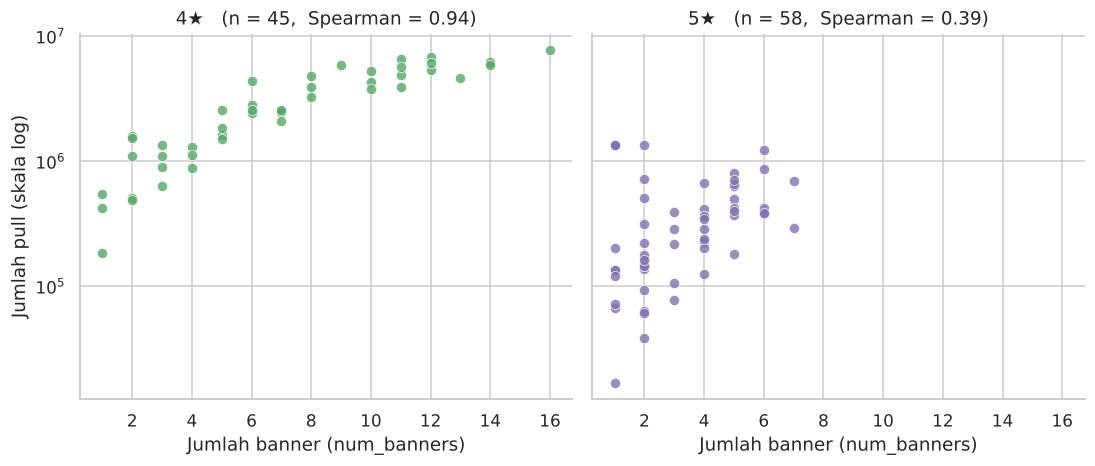

         min  median  max
bintang                  
4★         1     6.0   16
5★         1     3.0    7


In [6]:
g = sns.FacetGrid(df, col='bintang', col_order=['4★', '5★'], height=4.4, aspect=1.15, sharex=True, sharey=True,
                  hue='bintang', palette={'4★': '#55A868', '5★': '#8172B2'})
g.map_dataframe(sns.scatterplot, x='num_banners', y='pulled_count', s=45, alpha=.8)
g.set(yscale='log', xlabel='Jumlah banner (num_banners)', ylabel='Jumlah pull (skala log)')
for ax, r in zip(g.axes.flat, ['4★', '5★']):
    s = df[df['bintang'] == r]
    ax.set_title(f"{r}   (n = {len(s)},  Spearman = {stats.spearmanr(s['num_banners'], s['pulled_count'])[0]:.2f})")
plt.tight_layout(); plt.savefig(FIG + '/m3_facet_rarity.png', bbox_inches='tight'); plt.show()
print(df.groupby('bintang', observed=True)['num_banners'].agg(['min', 'median', 'max']).to_string())

**Tafsiran.** Pola **berbeda** antar rarity: di bintang 4 hubungannya hampir monoton (Spearman 0,94; n = 45), tetapi di bintang 5 jauh lebih lemah (0,39; n = 58).
Korelasi gabungan 0,70 adalah campuran dua kelompok: bintang 4 sekaligus tampil di lebih banyak banner (median 6, maksimum 16) dan ber-*pull* lebih besar, sedangkan bintang 5 hanya tampil di 1–7 banner (median 3).
Jadi "karakter yang lebih sering tampil cenderung ber-*pull* lebih besar" berlaku kuat untuk bintang 4 saja. Keterbatasan: n kecil dan `num_banners` bernilai bulat dengan banyak titik bertumpuk.

## 5. Kandidat variabel perancu (*confounder*)
Uji: bila `rarity` adalah perancu pada pasangan `duplicate_rate`–`pulled_count`, korelasinya harus **berubah** setelah rarity dikendalikan.

Seluruh data      : {'n': 103, 'spearman': np.float64(0.57), 'pearson': np.float64(0.63)}
Di dalam 4★       : {'n': 45, 'spearman': np.float64(-0.15), 'pearson': np.float64(-0.14)}
Di dalam 5★       : {'n': 58, 'spearman': np.float64(-0.24), 'pearson': np.float64(-0.35)}

         duplicate_rate  pulled_count
bintang                              
4★                0.749     2542518.0
5★                0.202      288172.0


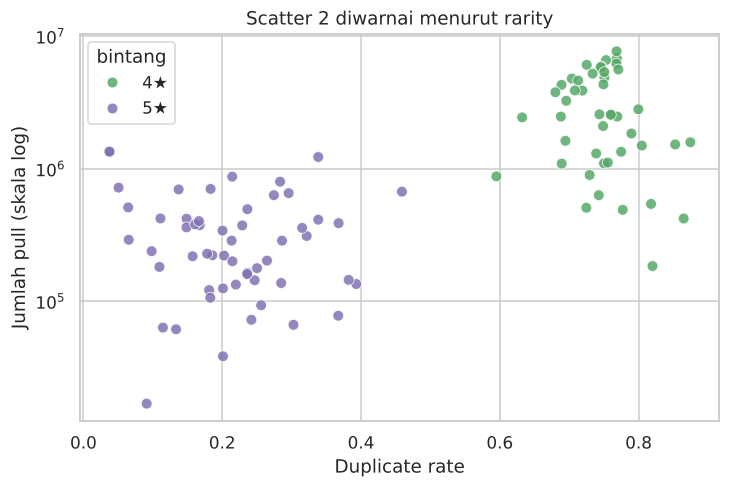

In [7]:
print('Seluruh data      :', lapor('duplicate_rate', 'pulled_count'))
for r, s in df.groupby('bintang', observed=True):
    print(f'Di dalam {r}       :', lapor('duplicate_rate', 'pulled_count', data=s))
print()
print(df.groupby('bintang', observed=True)[['duplicate_rate', 'pulled_count']].median().round(3).to_string())

fig, ax = plt.subplots(figsize=(6.8, 4.6))
sns.scatterplot(data=df, x='duplicate_rate', y='pulled_count', hue='bintang', hue_order=['4★', '5★'],
                palette={'4★': '#55A868', '5★': '#8172B2'}, s=50, alpha=.85, ax=ax)
ax.set(yscale='log', xlabel='Duplicate rate', ylabel='Jumlah pull (skala log)', title='Scatter 2 diwarnai menurut rarity')
plt.tight_layout(); plt.savefig(FIG + '/m3_scatter2_warna_rarity.png', bbox_inches='tight'); plt.show()

**Paragraf kandidat perancu.**
**`rarity` (bersama status banner standar) sangat mungkin menjadi perancu.** Karakter bintang 4 memiliki `duplicate_rate` lebih tinggi (median 0,75 vs 0,20) sekaligus jumlah *pull* jauh lebih besar (median ≈ 2,54 juta vs ≈ 288 ribu).
Karena itu, bila digabung, `duplicate_rate` dan *pull* tampak berhubungan **positif** (Spearman 0,57), padahal **di dalam tiap kelompok rarity arahnya berbalik menjadi lemah dan negatif**: −0,15 (bintang 4) dan −0,24 (bintang 5).
Hubungan di data gabungan sepenuhnya berasal dari perbedaan antar-kelompok, bukan dari `duplicate_rate` itu sendiri.
**Perancu kedua:** *paparan* (usia rilis dan jumlah banner), yang saling berkaitan kuat (Spearman 0,71) dan sama-sama berkaitan dengan *pull*; pengaruhnya tidak bisa dipisahkan di data ini,
terlebih karena `days_since_release` sudah dibuang di `01_quality` dan usia hanya tersisa 5 kelompok kasar. Dicatat sebagai keterbatasan.

## 6. Uji sensitivitas: baris `pulled_tidak_cocok`
Dari `02_cleaning`, 9 baris memiliki `pulled_count` yang tidak sama dengan total C0–C7 (selisih kecil). Baris itu **ditandai, bukan dibuang**. Pertanyaannya: **apakah kesimpulan utama berubah bila baris itu dikeluarkan?**

In [8]:
skenario = {'Semua baris': np.ones(len(df), bool), 'Tanpa pulled_tidak_cocok': ~df['pulled_tidak_cocok']}
hasil = {}
for nama, m in skenario.items():
    s = df[m]; k = {'n (semua)': len(s), 'n bintang 4': int((s.bintang == '4★').sum()), 'n bintang 5': int((s.bintang == '5★').sum())}
    for x, lab in [('num_banners', 'banner~pull'), ('duplicate_rate', 'dup~pull'), ('usia_rilis_kode', 'usia~pull')]:
        k[f'{lab} (semua)'] = lapor(x, 'pulled_count', s)['spearman']
        for r in ['4★', '5★']:
            k[f'{lab} ({r})'] = lapor(x, 'pulled_count', s[s.bintang == r])['spearman']
    k['median pull (semua)'] = s['pulled_count'].median()
    hasil[nama] = k
tabel = pd.DataFrame(hasil); tabel['selisih'] = (tabel['Tanpa pulled_tidak_cocok'] - tabel['Semua baris']).round(2)
display(tabel)

,Semua baris,Tanpa pulled_tidak_cocok,selisih
n (semua),103.00,94.00,-9.00
n bintang 4,45.00,38.00,-7.00
n bintang 5,58.00,56.00,-2.00
banner~pull (semua),0.70,0.66,-0.04
banner~pull (4★),0.94,0.93,-0.01
banner~pull (5★),0.39,0.38,-0.01
dup~pull (semua),0.57,0.53,-0.04
dup~pull (4★),-0.15,-0.12,0.03
dup~pull (5★),-0.24,-0.28,-0.04
usia~pull (semua),0.61,0.63,0.02


**Tafsiran.** Kesimpulan **tidak berubah**: seluruh koefisien Spearman bergeser paling banyak 0,04 (misalnya `banner~pull` gabungan 0,70 menjadi 0,66; `dup~pull` di bintang 5 −0,24 menjadi −0,28; usia~pull di bintang 4 tetap 0,92).
Yang bergeser nyata adalah **median *pull***, dari 652 ribu menjadi 525 ribu (−19,5%). Penyebabnya bukan kesalahan 1–3 *pull* di baris itu, melainkan **hilangnya karakter**: 7 dari 9 baris tersebut bintang 4,
sehingga mengeluarkannya menghapus sekitar 16% (7 dari 45) kelompok ber-*pull* terbesar. Ini mendukung keputusan untuk **tidak membuang baris**.
Catatan: `banner_belum_selesai` yang dipakai di versi pembersihan lain tidak bisa dibuat di sini karena `banner_dates` dibuang di `01_quality`.

## 7. Ringkasan temuan, dikaitkan dengan pertanyaan

| Pertanyaan | Temuan (kata kerja hati-hati) | Bukti |
|---|---|---|
| **P1** Sebaran *pull* | Sangat miring ke kanan; yang "ekstrem" semuanya bintang 4 tetapi bukan outlier di dalam kelompoknya (notebook 03) | 03 bagian 2 |
| **P2** Usia rilis dan banner vs *pull* | Karakter yang lebih tua dan tampil di lebih banyak banner **cenderung disertai** *pull* lebih besar (usia 0,61; banner 0,70). Kuat di bintang 4 (banner 0,94), lemah di bintang 5 (0,39). Stabil terhadap uji sensitivitas | Bagian 2, 4, 6 |
| **P3** Rarity dan perancu | Rarity dan banner standar nyaris tumpang tindih (V = 0,86). Korelasi `duplicate_rate`–*pull* +0,57 berbalik menjadi −0,15 dan −0,24 setelah rarity dikendalikan | Bagian 3, 5 |

**Keterbatasan (spesifik).**
1. n = 103 karakter; per kelompok rarity hanya 45 dan 58, dan sel usia × rarity hanya 5–20, sehingga koefisien kasar dan tidak stabil.
2. Satuan analisis adalah karakter, bukan pemain; cara menghitung `pulled_count` tidak didokumentasikan, sehingga "popularitas" adalah asumsi.
3. Variabel yang dibuang di `01_quality` (`days_since_release`, `release_date`, statistik HP/ATK/DEF, `banner_dates`) membatasi analisis: usia hanya 5 kelompok ordinal dan tidak bisa dipisahkan dari jumlah banner.
4. Karakter baru belum punya waktu tampil yang setara, sehingga usia rilis bercampur dengan kesempatan muncul.
5. Tidak ada klaim sebab-akibat.

## 8. Daftar periksa M3
- [ ] Setiap angka korelasi punya grafik (bagian 2, 4, 5)
- [ ] Pearson/Spearman dipilih beralasan dari sifat data (bagian 1)
- [ ] *n* yang dilaporkan adalah n setelah `dropna()`
- [ ] Panel yang disandingkan memakai sumbu dan skala warna yang sama (bagian 1, 4)
- [ ] Tidak ada kalimat sebab-akibat
- [ ] *Restart & Run All*, path relatif, data dibaca dari `data/processed/`
- [ ] Tag Git `m3` sudah dibuat dan di-push